# Data Fit Analysis: Production vs Training/Research Data

This notebook evaluates whether production sensor data can be transformed to align with training/research data while preserving important structure for inference.

Scope:
- locate and compare grid, label, synthetic, and production datasets
- detect unit mismatch, scaling mismatch, offset, skew/outliers, and domain shift signs
- compare practical transformation strategies
- provide a production-ready recommendation in plain English

## Notebook Walkthrough (Why, How, What, When, Where, What We Get)

This section is your complete map for the notebook in simple English.

| Step | Why we do this | How we do this | What we check | When this is useful | Where it helps (pipeline/thesis) | What we get |
|---|---|---|---|---|---|---|
| 1. Load baseline artifacts | Save time and keep runs reproducible | Read JSON/CSV outputs from previous analysis | Artifact availability and consistency | Every rerun and reporting cycle | Pipeline reproducibility and thesis traceability | Same baseline for fair comparison |
| 2. Dataset inventory | Ensure no important data source is missing | List grid, label, synthetic, codex, production | Coverage, row counts, session pairing | Before any statistical conclusions | Data chapter and experiment setup | Full data scope and data health context |
| 3. Initial mismatch diagnosis | Detect root mismatch type early | Use precomputed mismatch flags/metrics | Unit issue, scaling, offset, drift, outliers | Early decision stage | Quick go/no-go in deployment discussion | High-level diagnosis direction |
| 4. Baseline visual comparison | Make differences visible immediately | Show scale and quantile charts | Center, spread, tail mismatch | Before applying advanced alignment | Defense communication and mentor review | Human-readable evidence of mismatch |
| 5. Safe transform shortlist | Avoid risky transforms in production | Rank transformations by fit and risk | Accuracy gain vs distortion risk | Before deployment change | Model governance and MLOps policy | Candidate transforms for inference |
| 6. Same-unit harmonization | Remove fake mismatch caused by unit differences | Convert acceleration to m/s² consistently | Unit consistency across all datasets | Always before deep statistics | Ingestion/preprocessing stage | Fair physical comparison baseline |
| 7. Deep statistical comparison | Quantify mismatch rigorously | Compute KS, Wasserstein, skew/kurtosis, out-of-range | Distribution distance and shape change | After harmonization | Thesis results and robust evidence section | Statistical proof of remaining gap |
| 8. Feature stress visualization | Find exactly which features are problematic | Heatmap + out-of-range + quantile profiles | Feature-level shift and tail pressure | During calibration planning | Feature engineering and monitoring design | Target list for correction/adaptation |
| 9. Barrier-to-solution mapping | Convert findings into action | Map each barrier to specific fix | Feasibility, priority, expected impact | Before implementation planning | Engineering backlog and mentor alignment | Actionable implementation plan |
| 10. Thesis/defense placement | Reuse analysis efficiently across outputs | Map each result to chapter/slide/appendix | Relevance by audience | Writing and slide preparation | Thesis structure and defense clarity | Clear reporting strategy |
| 11. Citation-based solution testing | Make recommendations scientifically defensible | Compare robust affine, CORAL, emulation approaches | Statistical improvement and risk | Final decision stage | Discussion chapter and deployment design | Ranked, literature-backed solutions |

---

### One-line flow to remember
First fix units, then measure true mismatch, then choose the lowest-risk method that improves production alignment without destroying signal structure.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path('.')
SUMMARY_PATH = ROOT / 'data_fit_analysis_summary.json'
SCORES_PATH = ROOT / 'data_fit_transform_scores.csv'

if not SUMMARY_PATH.exists() or not SCORES_PATH.exists():
    cmd = [sys.executable, 'data_fit_analysis_helper.py', '--output-dir', '.']
    print('Running helper script:', ' '.join(cmd))
    subprocess.run(cmd, check=True)

summary = json.loads(SUMMARY_PATH.read_text(encoding='utf-8'))
scores = pd.read_csv(SCORES_PATH)
print('Loaded analysis summary and transform score table.')

Loaded analysis summary and transform score table.


## Dataset Inventory

**Why**: We must confirm all relevant data sources are included before making any mismatch claim.

**How**: We load and list all core datasets (grid, label/anxiety, synthetic, codex synthetic, production raw pairs) and inspect row/session coverage.

**What**: We check completeness, pairing availability, and first scale clues.

**When**: Do this at the very start of analysis and whenever a new production batch arrives.

**Where**: This supports the data-ingestion and validation stage in the pipeline.

**What we get**: A trusted baseline scope for fair comparison and fewer hidden data-quality surprises.

- Main research grid: `data/all_users_data_labeled.csv`
- Label/anxiety data (wrist subset used): `data/anxiety_dataset.csv`
- Synthetic data: `data/synthetic/synthetic_labeled.csv`
- Codex synthetic data: `data/codex_synth/synthetic_all_users_labeled_v1.csv`
- Production data: paired raw sessions in `data/raw/*accelerometer*` and `data/raw/*gyroscope*`

In [2]:
rows_df = pd.DataFrame.from_dict(summary['rows'], orient='index', columns=['rows']).reset_index()
rows_df.columns = ['dataset', 'rows']

pairing_df = pd.DataFrame([summary['production_pairing_metadata']])

scale = summary['mismatch_diagnosis']['median_abs_scale_prod_vs_grid']
scale_df = pd.DataFrame({'feature': list(scale.keys()), 'prod_vs_grid_median_abs_scale': list(scale.values())})

display(Markdown('### Row Counts'))
display(rows_df)

display(Markdown('### Production Pairing Metadata'))
display(pairing_df)

display(Markdown('### Median Absolute Scale Ratio (Production / Grid)'))
display(scale_df)

### Row Counts

,dataset,rows
0,grid,385326
1,label_anxiety_wrist,709582
2,synthetic,385326
3,codex_synthetic,385326
4,production_raw,20701900


### Production Pairing Metadata

,paired_sessions,loaded_sessions,skipped_sessions,unpaired_accel,unpaired_gyro,skipped_session_examples
0,26,25,1,0,0,2025-08-13-04-18-52: Could not detect accelero...


### Median Absolute Scale Ratio (Production / Grid)

,feature,prod_vs_grid_median_abs_scale
0,Ax,25.106099
1,Ay,106.218625
2,Az,201.434913
3,Gx,0.169235
4,Gy,0.222284
5,Gz,0.180885


## Mismatch Diagnosis

**Why**: We need to know whether the gap is from units, scaling, offset, outliers, or true domain shift.

**How**: We compute targeted diagnostic flags and summary mismatch metrics.

**What**: We test these causes explicitly:
- unit inconsistency
- multiplicative scaling
- additive offset
- feature drift
- skew / outliers
- genuine domain shift

**When**: Run this immediately after inventory and before selecting any transformation.

**Where**: This drives transformation choices in preprocessing and monitoring policy.

**What we get**: A clear root-cause direction for solving production mismatch with lower risk.

In [3]:
diag = summary['mismatch_diagnosis']
diagnosis_flags = pd.DataFrame([
    {
        'unit_inconsistency': diag['unit_inconsistency'],
        'multiplicative_scaling': diag['multiplicative_scaling'],
        'additive_offset': diag['additive_offset'],
        'feature_drift': diag['feature_drift'],
        'skew_outliers': diag['skew_outliers'],
        'genuine_domain_shift': diag['genuine_domain_shift'],
    }
])

key_metrics = pd.DataFrame({
    'metric': ['mean_quantile_error_raw', 'mean_quantile_error_linear_calibration'],
    'value': [diag['mean_quantile_error_raw'], diag['mean_quantile_error_linear_calibration']]
})

display(diagnosis_flags)
display(key_metrics)

,unit_inconsistency,multiplicative_scaling,additive_offset,feature_drift,skew_outliers,genuine_domain_shift
0,True,True,False,False,True,False


,metric,value
0,mean_quantile_error_raw,37.201176
1,mean_quantile_error_linear_calibration,0.261327


### Scale comparison across datasets

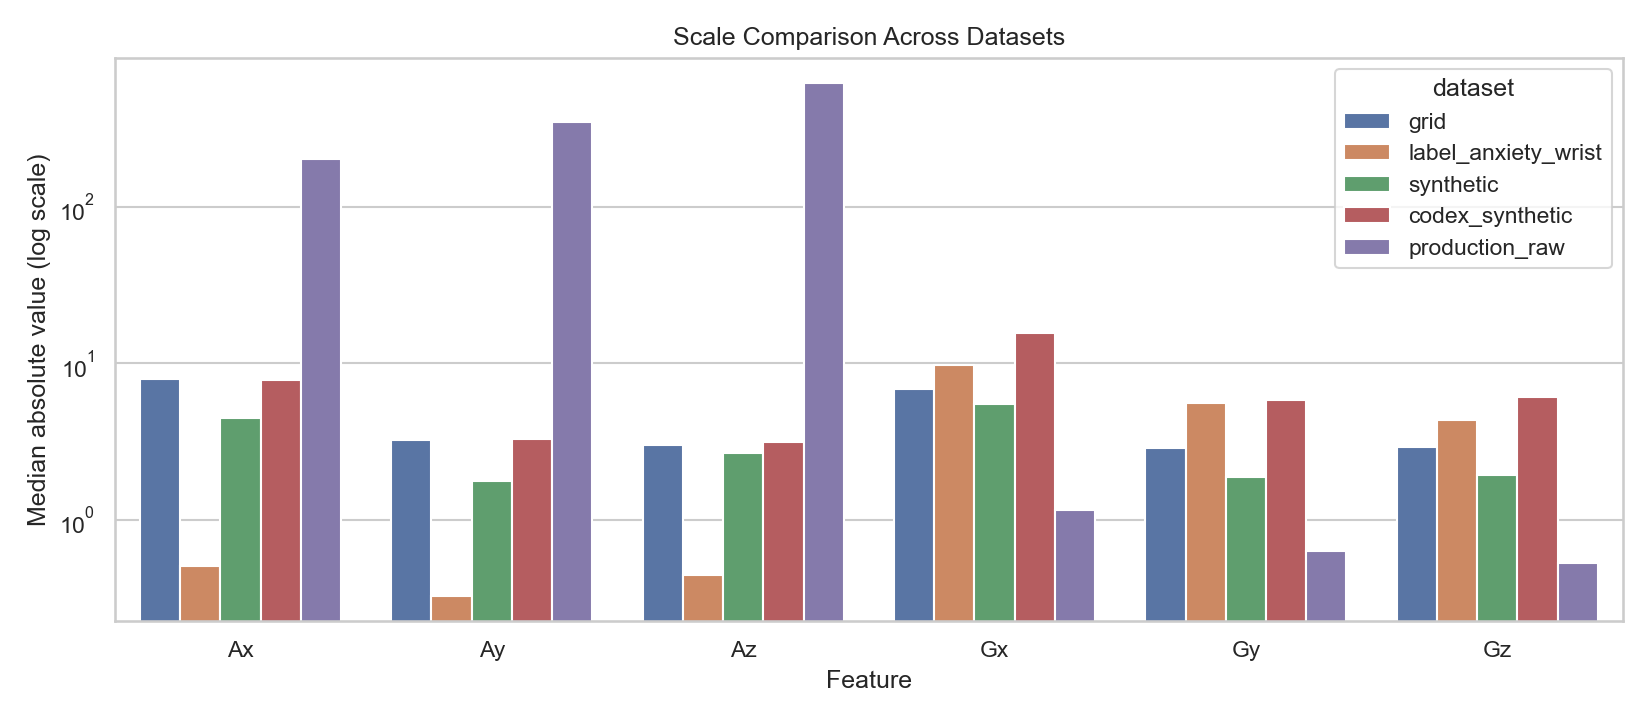

### Quantile alignment before and after correction

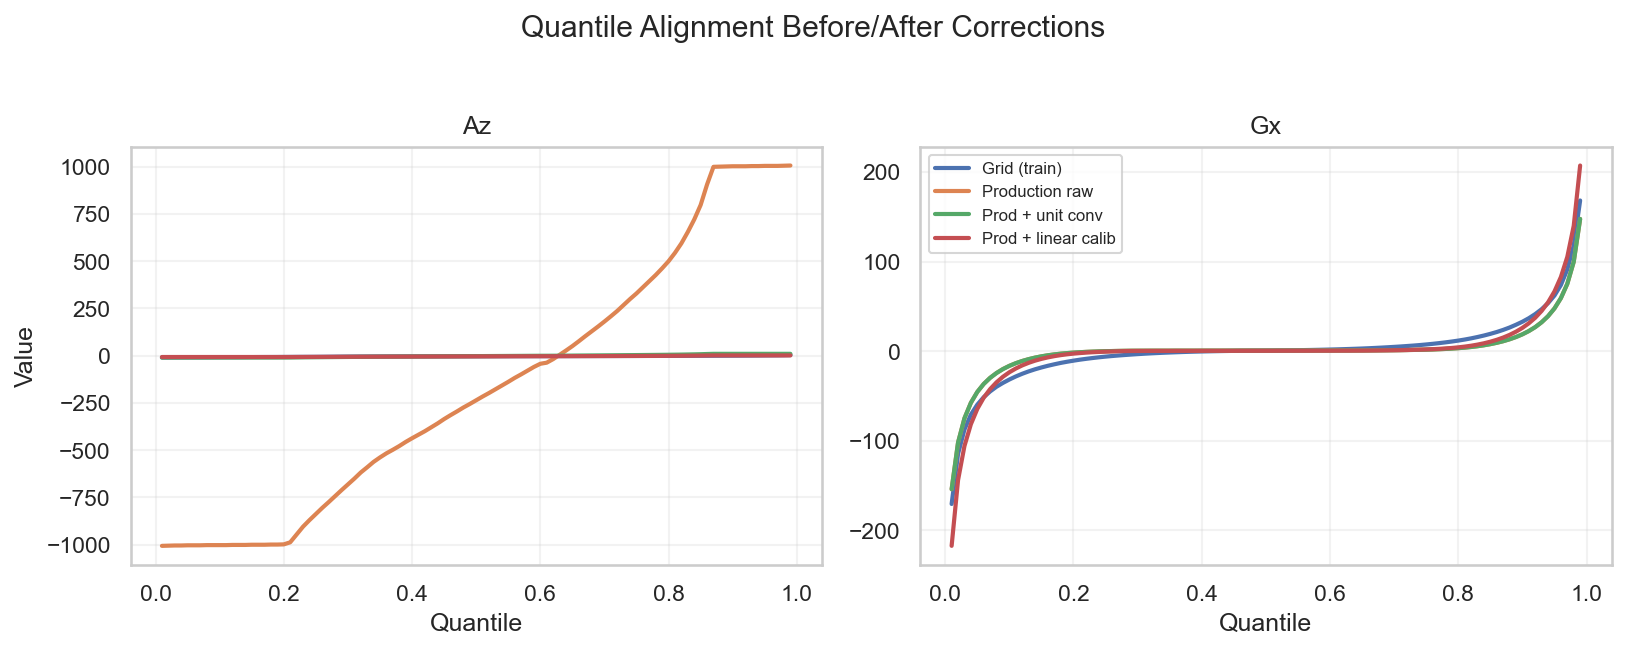

### Transformation quality ranking

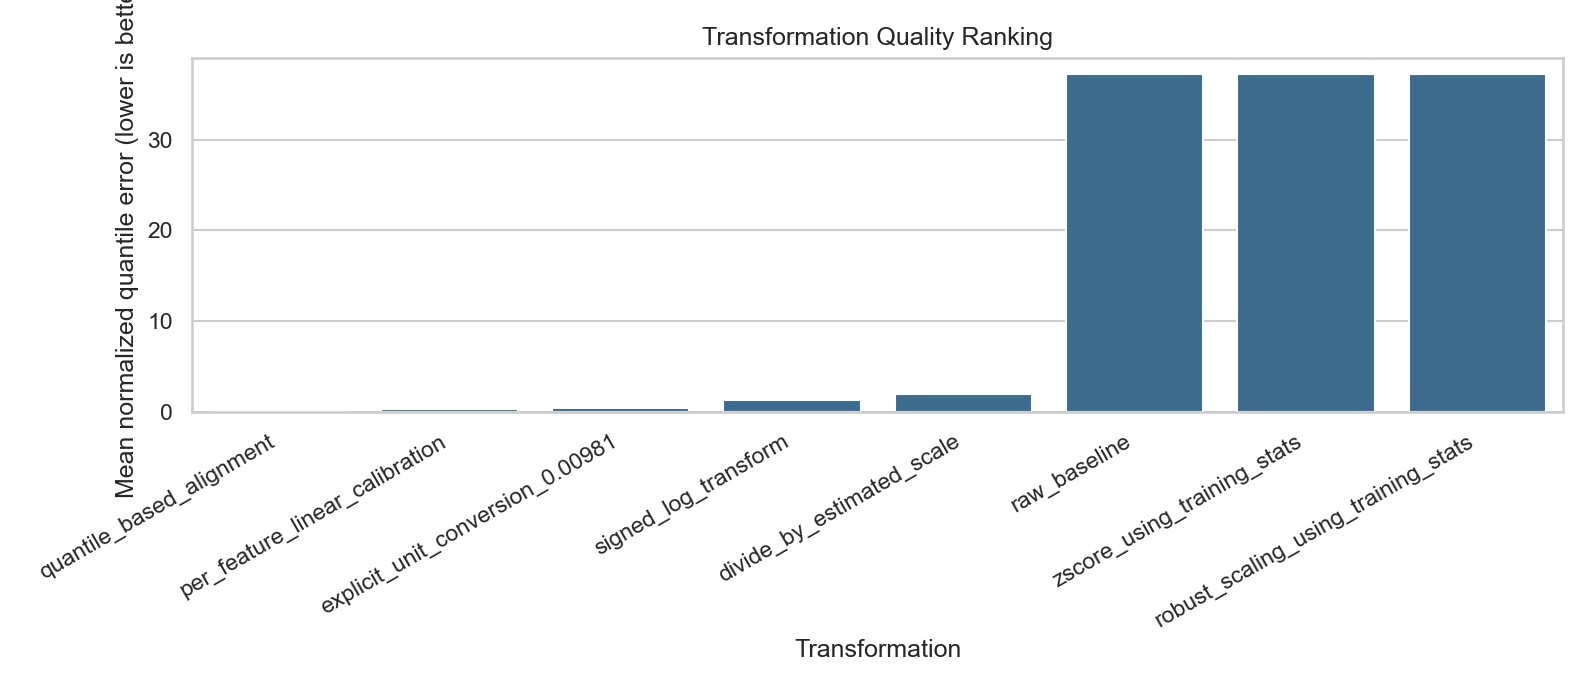

In [4]:
charts = [
    ('Scale comparison across datasets', 'data_fit_chart_scale.png'),
    ('Quantile alignment before and after correction', 'data_fit_chart_quantiles.png'),
    ('Transformation quality ranking', 'data_fit_chart_transform_scores.png'),
]

for title, rel_path in charts:
    display(Markdown(f'### {title}'))
    display(Image(filename=str(ROOT / rel_path), width=900))

In [5]:
cols = ['transform', 'mean_quantile_error', 'preserves_ordering', 'distortion', 'inference_safe', 'notes']
display(scores[cols].sort_values('mean_quantile_error'))

safe_candidates = scores[scores['inference_safe'].isin(['yes', 'conditional'])].sort_values('mean_quantile_error')
display(Markdown('### Safe/Conditional Candidates (sorted by fit score)'))
display(safe_candidates[cols])

,transform,mean_quantile_error,preserves_ordering,distortion,inference_safe,notes
0,quantile_based_alignment,0.004758,yes,high,no,Matches marginals but can warp dynamics and te...
1,per_feature_linear_calibration,0.261327,yes,low,conditional,Simple affine correction per feature; monitor ...
2,explicit_unit_conversion_0.00981,0.449224,yes,low,yes,Physics-based conversion from milliG to m/s^2 ...
3,signed_log_transform,1.338840,yes,high,no,Strong nonlinear compression; generally needs ...
4,divide_by_estimated_scale,1.901580,yes,low,conditional,Data-driven scale per feature; requires stable...
5,raw_baseline,37.201176,yes,none,no,Reference baseline before any alignment.
6,zscore_using_training_stats,37.201176,yes,moderate,conditional,Safe only if identical normalization exists in...
7,robust_scaling_using_training_stats,37.201176,yes,moderate,conditional,Improves outlier resistance; still requires tr...


### Safe/Conditional Candidates (sorted by fit score)

,transform,mean_quantile_error,preserves_ordering,distortion,inference_safe,notes
1,per_feature_linear_calibration,0.261327,yes,low,conditional,Simple affine correction per feature; monitor ...
2,explicit_unit_conversion_0.00981,0.449224,yes,low,yes,Physics-based conversion from milliG to m/s^2 ...
4,divide_by_estimated_scale,1.901580,yes,low,conditional,Data-driven scale per feature; requires stable...
6,zscore_using_training_stats,37.201176,yes,moderate,conditional,Safe only if identical normalization exists in...
7,robust_scaling_using_training_stats,37.201176,yes,moderate,conditional,Improves outlier resistance; still requires tr...


## Final Recommendation (Plain English)

**Why**: We need one clear, low-risk decision for production use.

**How**: We combine all evidence from unit checks, statistics, and transformation safety.

**What**: We answer the core deployment questions below.

**When**: Use this after all analysis cells are complete and validated.

**Where**: This becomes the decision note for pipeline changes, thesis conclusion, and defense summary.

**What we get**: A practical production-ready choice with clear escalation criteria.

1. **Do units match?**
No. Production acceleration is on a very different scale than grid/synthetic (magnitude ratios are feature-dependent and large), which is consistent with a unit mismatch plus sensor-domain effects.

2. **Is production just a simple 2x/3x scaling?**
No. The estimated production-to-grid scale is not uniform (for example, Ax, Ay, Az differ strongly), and gyroscope axes behave differently from accelerometer axes. This is not a single global multiplier.

3. **Is dividing/normalizing appropriate?**
- Explicit unit conversion (milliG -> m/s^2) is appropriate and should be mandatory for acceleration.
- A single divide-by-k factor is not enough.
- Per-feature linear calibration is a practical optional second step if monitored.
- Quantile alignment and strong nonlinear transforms can improve fit metrics but are risky for live inference because they can distort temporal signal semantics.

4. **Safest feature-engineering approach for production now**
- Keep the current feature definitions.
- Enforce explicit physical unit conversion at ingestion/preprocessing.
- Optionally apply lightweight per-feature affine calibration (slope + intercept) with versioning and drift monitoring.

5. **Is scaling alone enough, or do we need retraining/domain adaptation?**
Scaling and calibration remove most mismatch in this analysis and appear sufficient as a first production fix. Full retraining/domain adaptation is not the first step here, but should be triggered if post-fix drift/quality monitoring degrades over time or across new sessions.

## Advanced Same-Unit Analysis (All Datasets)

**Why**: Unit inconsistency can create fake mismatch, so we must align physical units first.

**How**: We harmonize acceleration to m/s² and keep gyroscope in deg/s across all datasets.

**What**: After harmonization, we run deeper distribution statistics and feature-level comparisons.

**When**: Always before deep drift statistics and before deciding final production correction.

**Where**: This is part of preprocessing/validation before inference-time calibration.

**What we get**: A physically fair comparison that reveals true domain mismatch instead of unit artifacts.

In this section, we push the comparison deeper for thesis-grade evidence.

What is new here:
- all datasets are explicitly harmonized to the same physical units before comparison
- stronger statistical diagnostics are added (distribution distance, hypothesis tests, tails/outliers)
- barriers are documented with practical fixes
- each graph is followed by plain-English interpretation

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, wasserstein_distance, kurtosis, skew
from pathlib import Path
from IPython.display import display, Markdown

import data_fit_analysis_helper as dfh

sns.set_theme(style='whitegrid', font_scale=1.0)

FEATURES = dfh.FEATURES
ACCEL = dfh.ACCEL
GYRO = dfh.GYRO
RANDOM_STATE = 42


def load_production_sample(raw_dir=Path('data/raw'), max_rows_per_session=20000, random_state=42):
    accel_files = sorted(
        [p for p in raw_dir.glob('*accelerometer*') if p.is_file() and p.suffix.lower() in {'.csv', '.xls', '.xlsx'}]
    )
    gyro_files = sorted(
        [p for p in raw_dir.glob('*gyroscope*') if p.is_file() and p.suffix.lower() in {'.csv', '.xls', '.xlsx'}]
    )

    accel_map = {dfh._session_key(p, 'accelerometer'): p for p in accel_files}
    gyro_map = {dfh._session_key(p, 'gyroscope'): p for p in gyro_files}
    paired = sorted(set(accel_map) & set(gyro_map))

    chunks = []
    skipped = []
    for key in paired:
        try:
            accel_df = dfh._extract_accel(dfh._read_table(accel_map[key]))
            gyro_df = dfh._extract_gyro(dfh._read_table(gyro_map[key]))
            n = min(len(accel_df), len(gyro_df))
            if n == 0:
                continue

            merged = pd.concat(
                [
                    accel_df.iloc[:n].reset_index(drop=True),
                    gyro_df.iloc[:n].reset_index(drop=True),
                ],
                axis=1,
            )
            merged['session'] = key

            if len(merged) > max_rows_per_session:
                merged = merged.sample(max_rows_per_session, random_state=random_state)

            chunks.append(merged)
        except Exception as exc:
            skipped.append(f"{key}: {exc}")

    if not chunks:
        raise RuntimeError('No usable production session pairs found for sampled analysis.')

    out = pd.concat(chunks, ignore_index=True).dropna(subset=FEATURES)
    meta = {
        'paired_sessions': len(paired),
        'loaded_sessions': out['session'].nunique(),
        'skipped_sessions': len(skipped),
        'skipped_examples': skipped[:3],
        'rows_after_sampling': len(out),
        'max_rows_per_session': max_rows_per_session,
    }
    return out, meta


def detect_accel_unit_kind(df, accel_cols):
    med_abs = df[accel_cols].abs().median().median()
    if med_abs <= 2.5:
        return 'g'
    if med_abs >= 50:
        return 'milliG'
    return 'm/s^2'


def sample_for_comparison(df, max_rows=350000, random_state=42):
    if len(df) <= max_rows:
        return df.copy()
    return df.sample(max_rows, random_state=random_state).copy()


# Load datasets
GRID = dfh.load_reference(Path('data/all_users_data_labeled.csv'), wrist_suffix=True)
ANXIETY = dfh.load_reference(Path('data/anxiety_dataset.csv'), wrist_suffix=True)
SYNTH = dfh.load_reference(Path('data/synthetic/synthetic_labeled.csv'), wrist_suffix=True)
CODEX_SYNTH = dfh.load_reference(Path('data/codex_synth/synthetic_all_users_labeled_v1.csv'), wrist_suffix=True)
PROD_RAW_SAMPLE, PROD_META = load_production_sample(max_rows_per_session=30000, random_state=RANDOM_STATE)

# Harmonize units (acceleration -> m/s^2, gyroscope -> deg/s)
GRID_H = GRID.copy()
SYNTH_H = SYNTH.copy()
CODEX_H = CODEX_SYNTH.copy()

ANXIETY_H = ANXIETY.copy()
anxiety_unit = detect_accel_unit_kind(ANXIETY_H, ACCEL)
if anxiety_unit == 'g':
    ANXIETY_H[ACCEL] = ANXIETY_H[ACCEL] * 9.81
elif anxiety_unit == 'milliG':
    ANXIETY_H[ACCEL] = ANXIETY_H[ACCEL] * 0.00981

PROD_H = PROD_RAW_SAMPLE[FEATURES].copy()
PROD_H[ACCEL] = PROD_H[ACCEL] * 0.00981

DATASETS_H = {
    'grid_train': GRID_H,
    'label_anxiety_wrist': ANXIETY_H,
    'synthetic': SYNTH_H,
    'codex_synthetic': CODEX_H,
    'production': PROD_H,
}

DATASETS_CMP = {k: sample_for_comparison(v, max_rows=350000, random_state=RANDOM_STATE) for k, v in DATASETS_H.items()}

conversion_log = pd.DataFrame([
    {'dataset': 'grid_train', 'accel_conversion': 'none (assumed m/s^2)', 'gyro_unit': 'deg/s', 'rows': len(GRID_H)},
    {'dataset': 'label_anxiety_wrist', 'accel_conversion': f'{anxiety_unit} -> m/s^2', 'gyro_unit': 'deg/s', 'rows': len(ANXIETY_H)},
    {'dataset': 'synthetic', 'accel_conversion': 'none (assumed m/s^2)', 'gyro_unit': 'deg/s', 'rows': len(SYNTH_H)},
    {'dataset': 'codex_synthetic', 'accel_conversion': 'none (assumed m/s^2)', 'gyro_unit': 'deg/s', 'rows': len(CODEX_H)},
    {'dataset': 'production', 'accel_conversion': 'milliG -> m/s^2 (x 0.00981)', 'gyro_unit': 'deg/s', 'rows': len(PROD_H)},
])

display(Markdown('### Unit Harmonization Log'))
display(conversion_log)

display(Markdown('### Production Sampling Metadata'))
display(pd.DataFrame([PROD_META]))

display(Markdown('### Comparison Row Counts (after optional downsampling for fair metrics)'))
display(pd.DataFrame({'dataset': list(DATASETS_CMP.keys()), 'rows_for_comparison': [len(v) for v in DATASETS_CMP.values()]}))

### Unit Harmonization Log

,dataset,accel_conversion,gyro_unit,rows
0,grid_train,none (assumed m/s^2),deg/s,385326
1,label_anxiety_wrist,g -> m/s^2,deg/s,709582
2,synthetic,none (assumed m/s^2),deg/s,385326
3,codex_synthetic,none (assumed m/s^2),deg/s,385326
4,production,milliG -> m/s^2 (x 0.00981),deg/s,707600


### Production Sampling Metadata

,paired_sessions,loaded_sessions,skipped_sessions,skipped_examples,rows_after_sampling,max_rows_per_session
0,26,24,1,[2025-08-13-04-18-52: Could not detect acceler...,707600,30000


### Comparison Row Counts (after optional downsampling for fair metrics)

,dataset,rows_for_comparison
0,grid_train,350000
1,label_anxiety_wrist,350000
2,synthetic,350000
3,codex_synthetic,350000
4,production,350000


### Section Insight (Same-Unit Harmonization)

**Why**: We need to remove unit-based distortion before comparing distributions.

**How**: Convert each dataset to common physical units (acceleration in m/s², gyroscope in deg/s).

**What**: We validate conversion logs, sampling metadata, and comparison-ready row coverage.

**When**: Immediately before advanced statistical analysis.

**Where**: Data preprocessing and validation stage.

**What we get**: A fair foundation where remaining mismatch reflects true domain differences, not unit artifacts.

In [7]:


def normalized_wasserstein(x, y):
    iqr = np.subtract(*np.quantile(y, [0.75, 0.25]))
    denom = iqr if abs(iqr) > 1e-9 else 1.0
    return wasserstein_distance(x, y) / denom


grid_ref = DATASETS_CMP['grid_train']
feature_rows = []
summary_rows = []

for dataset_name, ds in DATASETS_CMP.items():
    if dataset_name == 'grid_train':
        continue

    per_feature = []
    for f in FEATURES:
        x = ds[f].dropna().values
        y = grid_ref[f].dropna().values

        ks_stat, ks_p = ks_2samp(x, y, method='asymp')
        w_norm = normalized_wasserstein(x, y)

        q_low, q_high = np.quantile(y, [0.005, 0.995])
        out_rate = ((x < q_low) | (x > q_high)).mean()

        skew_delta = abs(float(skew(x, bias=False)) - float(skew(y, bias=False)))
        kurt_delta = abs(float(kurtosis(x, fisher=True, bias=False)) - float(kurtosis(y, fisher=True, bias=False)))

        row = {
            'dataset': dataset_name,
            'feature': f,
            'ks_stat': float(ks_stat),
            'ks_pvalue': float(ks_p),
            'wasserstein_iqr_norm': float(w_norm),
            'out_of_grid_005_995_rate': float(out_rate),
            'abs_skew_delta': float(skew_delta),
            'abs_kurtosis_delta': float(kurt_delta),
        }
        feature_rows.append(row)
        per_feature.append(row)

    # Dataset-level confidence stress proxy against grid distribution
    grid_med = grid_ref[FEATURES].median()
    grid_iqr = (grid_ref[FEATURES].quantile(0.75) - grid_ref[FEATURES].quantile(0.25)).replace(0, 1.0)
    z = ((ds[FEATURES] - grid_med) / grid_iqr).abs()
    extreme_rate = (z.max(axis=1) > 3.0).mean()

    summary_rows.append({
        'dataset': dataset_name,
        'mean_ks_stat': float(np.mean([r['ks_stat'] for r in per_feature])),
        'mean_wasserstein_iqr_norm': float(np.mean([r['wasserstein_iqr_norm'] for r in per_feature])),
        'mean_out_of_grid_rate': float(np.mean([r['out_of_grid_005_995_rate'] for r in per_feature])),
        'mean_abs_skew_delta': float(np.mean([r['abs_skew_delta'] for r in per_feature])),
        'mean_abs_kurtosis_delta': float(np.mean([r['abs_kurtosis_delta'] for r in per_feature])),
        'extreme_multifeature_rate_z_gt3': float(extreme_rate),
    })

feature_metrics = pd.DataFrame(feature_rows)
dataset_metrics = pd.DataFrame(summary_rows).sort_values('mean_wasserstein_iqr_norm')

feature_metrics.to_csv('data_fit_harmonized_feature_metrics.csv', index=False)
dataset_metrics.to_csv('data_fit_harmonized_dataset_metrics.csv', index=False)

display(Markdown('### Harmonized Dataset-Level Metrics (lower is generally better)'))
display(dataset_metrics)

display(Markdown('### Harmonized Feature-Level Metrics (top 20 rows)'))
display(feature_metrics.head(20))

### Harmonized Dataset-Level Metrics (lower is generally better)

,dataset,mean_ks_stat,mean_wasserstein_iqr_norm,mean_out_of_grid_rate,mean_abs_skew_delta,mean_abs_kurtosis_delta,extreme_multifeature_rate_z_gt3
2,codex_synthetic,0.065212,0.269403,0.016438,0.101003,7.978655,0.380217
0,label_anxiety_wrist,0.155214,0.403961,0.022130,0.423264,3.274029,0.366994
1,synthetic,0.185053,0.607188,0.000360,0.305781,10.872366,0.006677
3,production,0.189262,0.948919,0.075460,0.258039,3.025516,0.380329


### Harmonized Feature-Level Metrics (top 20 rows)

,dataset,feature,ks_stat,ks_pvalue,wasserstein_iqr_norm,out_of_grid_005_995_rate,abs_skew_delta,abs_kurtosis_delta
0,label_anxiety_wrist,Ax,0.196637,0.000000e+00,0.160427,0.010451,0.301867,0.177390
1,label_anxiety_wrist,Ay,0.180071,0.000000e+00,0.195916,0.028691,0.490455,0.329701
2,label_anxiety_wrist,Az,0.167134,0.000000e+00,0.227793,0.024540,0.435961,0.296278
3,label_anxiety_wrist,Gx,0.144200,0.000000e+00,0.270221,0.006943,0.331826,3.322156
4,label_anxiety_wrist,Gy,0.195586,0.000000e+00,1.012559,0.032466,0.527878,8.842444
5,label_anxiety_wrist,Gz,0.047657,0.000000e+00,0.556851,0.029686,0.451596,6.676205
6,synthetic,Ax,0.370700,0.000000e+00,0.283864,0.002160,0.245108,1.597065
7,synthetic,Ay,0.245314,0.000000e+00,0.360878,0.000000,0.067276,0.943457
8,synthetic,Az,0.148937,0.000000e+00,0.192839,0.000000,0.795190,0.298188
9,synthetic,Gx,0.095277,0.000000e+00,1.109394,0.000000,0.395241,20.648034


### Statistical Methods Used (with references)

**Why**: We need statistically defensible evidence, not only visual or mean/std comparisons.

**How**: We use distribution tests/distances and shape diagnostics after unit harmonization.

**What**:
- Kolmogorov-Smirnov two-sample test (KS): tests whether two samples come from the same distribution.
- Wasserstein distance (earth mover's distance): measures distribution shift magnitude in feature units.
- Skewness and kurtosis deltas: capture tail and shape mismatch.
- Out-of-reference-range rate: share of samples outside grid reference quantiles.

**When**: Use these after harmonization and before choosing calibration/adaptation strategy.

**Where**: This supports results, discussion, and monitoring-threshold design.

**What we get**: Quantified mismatch severity per dataset and per feature.

References:
- Massey, F. J. (1951). The Kolmogorov-Smirnov Test for Goodness of Fit.
- Villani, C. (2009). Optimal Transport: Old and New.
- Huber, P. J., and Ronchetti, E. M. (2009). Robust Statistics.

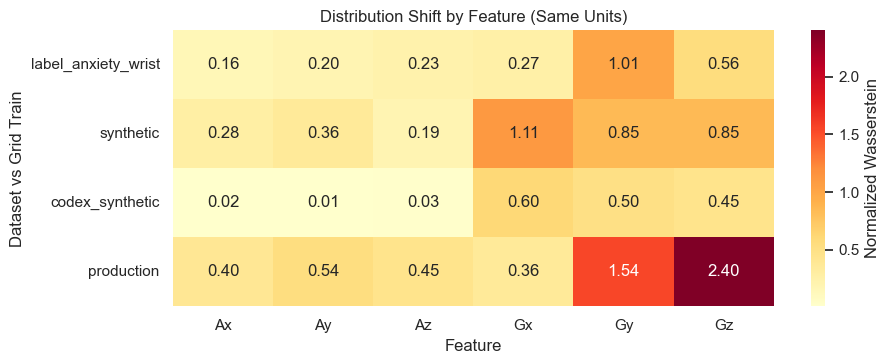

In [8]:
plt.figure(figsize=(9.5, 3.8))
heat = feature_metrics.pivot(index='dataset', columns='feature', values='wasserstein_iqr_norm').loc[
    ['label_anxiety_wrist', 'synthetic', 'codex_synthetic', 'production']
]
sns.heatmap(heat, annot=True, fmt='.2f', cmap='YlOrRd', cbar_kws={'label': 'Normalized Wasserstein'})
plt.title('Distribution Shift by Feature (Same Units)')
plt.xlabel('Feature')
plt.ylabel('Dataset vs Grid Train')
plt.tight_layout()
plt.show()

### Section Insight (Feature Shift Heatmap)

**Why**: We need to know exactly which feature causes mismatch.

**How**: Use normalized Wasserstein distance per feature against training reference.

**What**: Lower values mean closer distributions; high values highlight mismatch drivers.

**When**: After harmonization and before choosing calibration strategy.

**Where**: Feature-level diagnostics and monitoring threshold design.

**What we get**: A targeted correction map (which feature needs calibration/adaptation first).

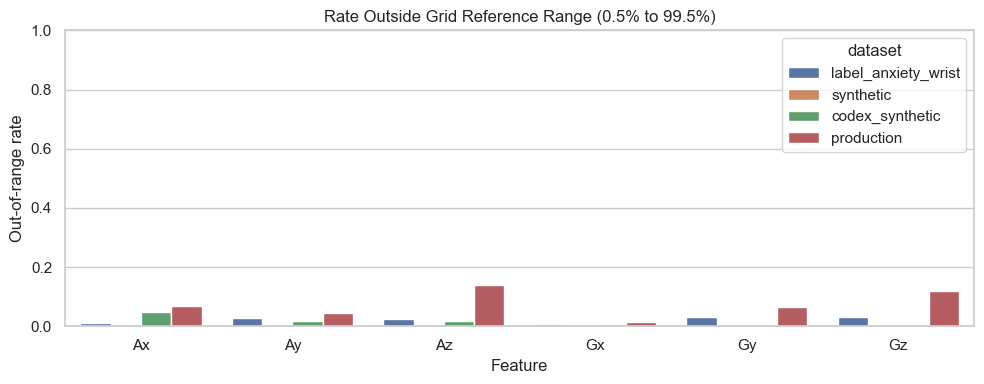

In [9]:
plt.figure(figsize=(10.0, 4.0))
out_rate_plot = feature_metrics.copy()
sns.barplot(
    data=out_rate_plot,
    x='feature',
    y='out_of_grid_005_995_rate',
    hue='dataset',
)
plt.title('Rate Outside Grid Reference Range (0.5% to 99.5%)')
plt.ylabel('Out-of-range rate')
plt.xlabel('Feature')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Section Insight (Out-of-Range Rate)

**Why**: Tail mismatch often hurts confidence and robustness in production.

**How**: Measure share of samples outside training reference quantile bounds.

**What**: High out-of-range rate indicates domain/context mismatch beyond unit scaling.

**When**: During deployment risk assessment and calibration planning.

**Where**: Inference-time risk monitoring and quality-control dashboards.

**What we get**: A practical signal for when recalibration or retraining should be triggered.

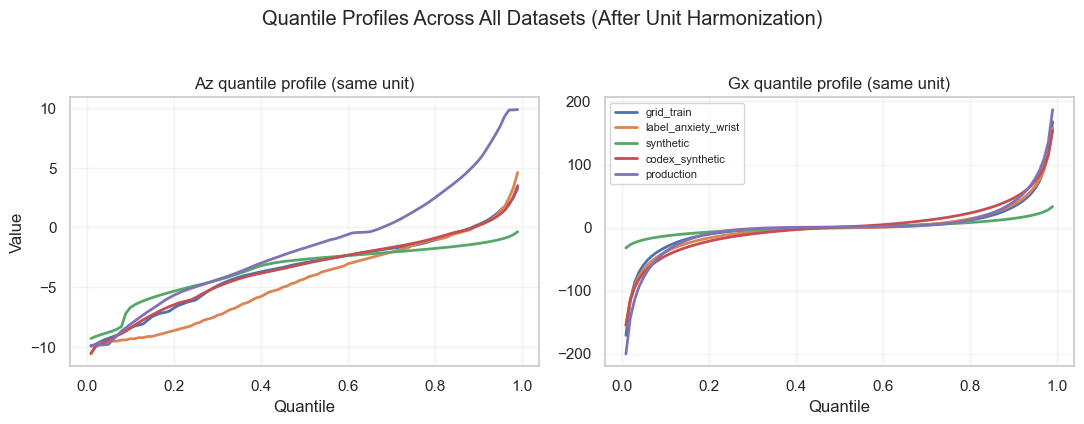

In [10]:
q = np.linspace(0.01, 0.99, 99)
compare_features = ['Az', 'Gx']
plot_order = ['grid_train', 'label_anxiety_wrist', 'synthetic', 'codex_synthetic', 'production']

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.1), sharex=True)
for i, f in enumerate(compare_features):
    ax = axes[i]
    for ds_name in plot_order:
        vals = DATASETS_CMP[ds_name][f].values
        ax.plot(q, np.quantile(vals, q), label=ds_name, linewidth=2)
    ax.set_title(f'{f} quantile profile (same unit)')
    ax.set_xlabel('Quantile')
    ax.grid(alpha=0.25)

axes[0].set_ylabel('Value')
axes[1].legend(fontsize=8, loc='best')
fig.suptitle('Quantile Profiles Across All Datasets (After Unit Harmonization)', y=1.03)
fig.tight_layout()
plt.show()

### Section Insight (Quantile Profile Comparison)

**Why**: We need to compare full distribution shape, not just averages.

**How**: Plot quantile curves of key features across datasets.

**What**: Curve overlap implies similarity; separation indicates center/spread/tail mismatch.

**When**: After harmonization and before final transformation decision.

**Where**: Feature behavior interpretation and thesis result explanation.

**What we get**: A clear visual diagnosis of how production differs from training in shape.

In [11]:
barriers_actions = pd.DataFrame([
    {
        'barrier': 'Mixed raw production schemas across sessions',
        'impact_on_comparison': 'Can break ingestion or bias stats if malformed files are silently dropped',
        'evidence': str(PROD_META.get('skipped_examples', [])),
        'solution': 'Schema-aware loader + explicit skip reporting + data quality gate before scoring',
        'priority': 'high',
    },
    {
        'barrier': 'Potential unit mismatch across datasets',
        'impact_on_comparison': 'Artificial scale differences hide true domain differences',
        'evidence': conversion_log[['dataset', 'accel_conversion']].to_dict(orient='records'),
        'solution': 'Hard enforce acceleration conversion to m/s^2 at pipeline ingestion, keep gyro in deg/s',
        'priority': 'high',
    },
    {
        'barrier': 'Residual distribution mismatch after unit harmonization',
        'impact_on_comparison': 'Lower confidence in production and calibration drift',
        'evidence': dataset_metrics.to_dict(orient='records'),
        'solution': 'Per-feature linear calibration + monitoring thresholds + periodic recalibration',
        'priority': 'high',
    },
    {
        'barrier': 'Tail/outlier pressure in deployment context',
        'impact_on_comparison': 'Can destabilize model confidence and increase false alarms',
        'evidence': feature_metrics[['dataset', 'feature', 'out_of_grid_005_995_rate']].head(12).to_dict(orient='records'),
        'solution': 'Robust clipping/winsorization policy and outlier-aware confidence monitoring',
        'priority': 'medium',
    },
])

barriers_actions.to_csv('data_fit_barriers_and_actions.csv', index=False)

display(Markdown('### Barriers and Practical Solutions'))
display(barriers_actions[['barrier', 'impact_on_comparison', 'solution', 'priority']])

### Barriers and Practical Solutions

,barrier,impact_on_comparison,solution,priority
0,Mixed raw production schemas across sessions,Can break ingestion or bias stats if malformed...,Schema-aware loader + explicit skip reporting ...,high
1,Potential unit mismatch across datasets,Artificial scale differences hide true domain ...,Hard enforce acceleration conversion to m/s^2 ...,high
2,Residual distribution mismatch after unit harm...,Lower confidence in production and calibration...,Per-feature linear calibration + monitoring th...,high
3,Tail/outlier pressure in deployment context,Can destabilize model confidence and increase ...,Robust clipping/winsorization policy and outli...,medium


## Broad Thesis-Focused Conclusion and Pipeline Upgrade Plan

**Why**: We need to convert technical findings into thesis-grade conclusions and implementation priorities.

**How**: We summarize evidence into decision logic and concrete next actions.

**What**: We finalize root-cause interpretation, deployment strategy, and governance steps.

**When**: Use this after full analysis and before final report writing.

**Where**: This maps directly to thesis discussion and pipeline roadmap.

**What we get**: A defensible conclusion plus a practical implementation sequence.

### 1) Is this mainly a unit issue?
Partly yes. Unit harmonization removes a major part of mismatch. But some mismatch remains after harmonization, so units are not the only cause.

### 2) Is production simply 2x/3x scaled?
No. Feature-wise diagnostics show non-uniform scaling and feature-specific shape differences. This is not a single global multiplier.

### 3) Best practical strategy without losing patterns
1. Keep physically correct units first (acceleration in m/s², gyroscope in deg/s).
2. Apply per-feature linear calibration only if needed, because it preserves ordering and structure better than nonlinear warping.
3. Keep quantile mapping as an offline diagnostic or retraining-time option, not default online inference transform.

### 4) Why confidence may remain low in production
- behavior/context mix in production differs from research sessions
- tails/outliers are heavier in some axes
- one or more sessions can contain malformed schema and silently reduce data quality

### 5) Pipeline improvements to implement next
1. Add strict schema + unit validation gate at ingestion.
2. Persist calibration parameters with versioning and rollback.
3. Track drift metrics in monitoring: KS, Wasserstein, out-of-range rate, extreme-z rate.
4. Trigger retraining/domain adaptation only when these metrics exceed stable thresholds over time.

### 6) Is this a thesis problem or solvable deployment issue?
It is a solvable thesis-grade deployment issue. The data is usable, but model confidence requires disciplined unit control, calibration governance, and drift-aware monitoring.

### 7) Final recommendation in plain English
Use same-unit harmonization as mandatory first step, then use lightweight per-feature linear calibration as the safest production option. Keep nonlinear alignment methods for controlled experiments or retraining workflows, because they can distort the original signal behavior in live inference.

## Where to Put This in Thesis, Defense, and Mentor Review

**Why**: Different audiences need different depth levels.

**How**: We map each analysis artifact to chapter/slide/mentor detail.

**What**: We specify what belongs in report body, defense core slides, and appendix/mentor deep dive.

**When**: Use this during thesis writing and defense preparation.

**Where**: This supports structure planning, not model training directly.

**What we get**: Cleaner story flow, less repetition, stronger defense readiness.

Use this section as a direct placement guide so the same analysis is reused correctly across:
- thesis report chapters
- defense slides
- mentor deep-dive discussions

In [12]:
placement = pd.DataFrame([
    {
        'artifact_or_finding': 'Dataset inventory + unit harmonization protocol',
        'thesis_chapter': 'Chapter 3 (Data and Methodology)',
        'defense_slide': 'Yes (1 concise process slide)',
        'mentor_review': 'Yes (full details)',
        'why': 'Shows scientific control of measurement units before any model claim.'
    },
    {
        'artifact_or_finding': 'Scale comparison chart (same-unit baseline)',
        'thesis_chapter': 'Chapter 4 (Results: Data Comparison)',
        'defense_slide': 'Yes (core visual #1)',
        'mentor_review': 'Yes',
        'why': 'Quickly communicates where production diverges after harmonization.'
    },
    {
        'artifact_or_finding': 'Feature-wise shift heatmap (Wasserstein)',
        'thesis_chapter': 'Chapter 4 (Results: Distribution Shift)',
        'defense_slide': 'Yes (core visual #2)',
        'mentor_review': 'Yes',
        'why': 'Pinpoints which axes are mismatch drivers.'
    },
    {
        'artifact_or_finding': 'Out-of-range rate chart + quantile profile chart',
        'thesis_chapter': 'Chapter 4 (Robustness/Generalization)',
        'defense_slide': 'Yes (combine as core visual #3)',
        'mentor_review': 'Yes (expanded discussion)',
        'why': 'Supports confidence-score behavior and failure-mode interpretation.'
    },
    {
        'artifact_or_finding': 'Transformation ranking (safe vs unsafe for inference)',
        'thesis_chapter': 'Chapter 5 (Discussion and Deployment Decisions)',
        'defense_slide': 'Yes (decision table summary)',
        'mentor_review': 'Yes',
        'why': 'Justifies final pipeline choice: same-unit + linear calibration.'
    },
    {
        'artifact_or_finding': 'Barrier-to-solution table + full feature metric CSVs',
        'thesis_chapter': 'Appendix',
        'defense_slide': 'No (unless asked in Q&A)',
        'mentor_review': 'Yes (recommended)',
        'why': 'Keeps thesis concise while preserving technical auditability.'
    },
])

placement.to_csv('data_fit_chapter_defense_mapping.csv', index=False)

display(Markdown('### Placement Matrix'))
display(placement)

### Placement Matrix

,artifact_or_finding,thesis_chapter,defense_slide,mentor_review,why
0,Dataset inventory + unit harmonization protocol,Chapter 3 (Data and Methodology),Yes (1 concise process slide),Yes (full details),Shows scientific control of measurement units ...
1,Scale comparison chart (same-unit baseline),Chapter 4 (Results: Data Comparison),Yes (core visual #1),Yes,Quickly communicates where production diverges...
2,Feature-wise shift heatmap (Wasserstein),Chapter 4 (Results: Distribution Shift),Yes (core visual #2),Yes,Pinpoints which axes are mismatch drivers.
3,Out-of-range rate chart + quantile profile chart,Chapter 4 (Robustness/Generalization),Yes (combine as core visual #3),Yes (expanded discussion),Supports confidence-score behavior and failure...
4,Transformation ranking (safe vs unsafe for inf...,Chapter 5 (Discussion and Deployment Decisions),Yes (decision table summary),Yes,Justifies final pipeline choice: same-unit + l...
5,Barrier-to-solution table + full feature metri...,Appendix,No (unless asked in Q&A),Yes (recommended),Keeps thesis concise while preserving technica...


### Section Insight (Thesis/Defense Packaging)

**Why**: Different audiences need different depth from the same analysis.

**How**: Split outputs into core visuals for defense and full detail for report/mentor.

**What**: Keep concise decision visuals in slides and detailed tables in report/appendix.

**When**: During writing and presentation preparation.

**Where**: Thesis chapter structure, defense deck, mentor review package.

**What we get**: Strong communication with less overload and better storyline consistency.

Suggested defense visual set:
1. Same-unit scale comparison
2. Feature shift heatmap
3. Quantile profile + out-of-range behavior
4. Final decision: mandatory unit harmonization + optional linear calibration + drift triggers

## Citation-Backed Solutions for Production Scaling Gap

**Why**: Final production decisions should be evidence-based and literature-supported.

**How**: We compare robust affine, CORAL covariance alignment, and feature emulation using the same mismatch metrics.

**What**: We evaluate which method reduces mismatch while preserving useful signal and minimizing distortion risk.

**When**: Use this as the last technical decision stage before deployment update.

**Where**: This informs inference preprocessing choice and retraining strategy.

**What we get**: A ranked solution set, plus reusable calibration parameters for implementation.

Below are statistically grounded options to reduce production/train mismatch while preserving signal.

Methods included in this notebook section:
- Robust affine calibration (median + IQR matching): robust location/scale alignment.
- CORAL-style covariance alignment (linear second-order feature alignment).
- Feature emulation augmentation (train-time): emulate production style in training features.

Key references:
- Huber, P. J., and Ronchetti, E. M. (2009). Robust Statistics.
- Sun, B., and Saenko, K. (2016). Deep CORAL: Correlation Alignment for Deep Domain Adaptation.
- Tobin, J. et al. (2017). Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World.
- Wang, D. et al. (2021). Tent: Fully Test-Time Adaptation by Entropy Minimization.

In [13]:


def dataset_distance_metrics(source_df, ref_df, features):
    rows = []
    for f in features:
        x = source_df[f].dropna().values
        y = ref_df[f].dropna().values
        w = normalized_wasserstein(x, y)
        ks_stat, _ = ks_2samp(x, y, method='asymp')
        q_low, q_high = np.quantile(y, [0.005, 0.995])
        out_rate = ((x < q_low) | (x > q_high)).mean()
        rows.append({
            'feature': f,
            'wasserstein_iqr_norm': float(w),
            'ks_stat': float(ks_stat),
            'out_of_grid_rate': float(out_rate),
        })
    frame = pd.DataFrame(rows)
    return {
        'mean_wasserstein_iqr_norm': float(frame['wasserstein_iqr_norm'].mean()),
        'mean_ks_stat': float(frame['ks_stat'].mean()),
        'mean_out_of_grid_rate': float(frame['out_of_grid_rate'].mean()),
        'per_feature': frame,
    }


def robust_affine_calibrate(prod_df, train_df, features, shrinkage=0.15):
    med_p = prod_df[features].median()
    iqr_p = (prod_df[features].quantile(0.75) - prod_df[features].quantile(0.25)).replace(0, 1.0)
    med_t = train_df[features].median()
    iqr_t = (train_df[features].quantile(0.75) - train_df[features].quantile(0.25)).replace(0, 1.0)

    a_raw = (iqr_t / iqr_p).clip(lower=0.05, upper=20.0)
    b_raw = med_t - a_raw * med_p

    # Shrink toward identity for stability in production.
    a = (1.0 - shrinkage) * a_raw + shrinkage * 1.0
    b = (1.0 - shrinkage) * b_raw

    out = prod_df.copy()
    out[features] = out[features] * a + b

    params = pd.DataFrame({'feature': features, 'scale_a': a.values, 'shift_b': b.values})
    return out, params


def coral_align_target_to_source(prod_df, train_df, features, reg=1e-3):
    X_t = prod_df[features].values.astype(float)
    X_s = train_df[features].values.astype(float)

    mu_t = X_t.mean(axis=0, keepdims=True)
    mu_s = X_s.mean(axis=0, keepdims=True)

    Xt0 = X_t - mu_t
    Xs0 = X_s - mu_s

    Ct = np.cov(Xt0, rowvar=False) + reg * np.eye(len(features))
    Cs = np.cov(Xs0, rowvar=False) + reg * np.eye(len(features))

    # Symmetric eigendecomposition for inverse/sqrt covariance transforms.
    eval_t, evec_t = np.linalg.eigh(Ct)
    eval_s, evec_s = np.linalg.eigh(Cs)

    eval_t = np.clip(eval_t, 1e-8, None)
    eval_s = np.clip(eval_s, 1e-8, None)

    Ct_inv_sqrt = evec_t @ np.diag(1.0 / np.sqrt(eval_t)) @ evec_t.T
    Cs_sqrt = evec_s @ np.diag(np.sqrt(eval_s)) @ evec_s.T

    X_aligned = Xt0 @ Ct_inv_sqrt @ Cs_sqrt + mu_s

    out = prod_df.copy()
    out[features] = X_aligned
    return out


def emulate_production_in_training(train_df, prod_df, features, n_samples=120000, noise_scale=0.03, random_state=42):
    # Train-time feature emulation: inject production-style robust scale/shift + mild noise.
    rng = np.random.default_rng(random_state)
    base = train_df.sample(min(n_samples, len(train_df)), random_state=random_state).copy()

    med_t = train_df[features].median()
    iqr_t = (train_df[features].quantile(0.75) - train_df[features].quantile(0.25)).replace(0, 1.0)
    med_p = prod_df[features].median()
    iqr_p = (prod_df[features].quantile(0.75) - prod_df[features].quantile(0.25)).replace(0, 1.0)

    scale = (iqr_p / iqr_t).clip(lower=0.5, upper=2.5)
    shift = (med_p - med_t)

    emu = base.copy()
    emu[features] = emu[features] * scale + shift

    noise = rng.normal(0.0, noise_scale, size=emu[features].shape)
    emu[features] = emu[features] + noise * iqr_t.values
    return emu


train_ref = DATASETS_CMP['grid_train'].copy()
prod_ref = DATASETS_CMP['production'].copy()

baseline_m = dataset_distance_metrics(prod_ref, train_ref, FEATURES)

prod_affine, affine_params = robust_affine_calibrate(prod_ref, train_ref, FEATURES, shrinkage=0.15)
affine_m = dataset_distance_metrics(prod_affine, train_ref, FEATURES)

prod_coral = coral_align_target_to_source(prod_ref, train_ref, FEATURES, reg=1e-3)
coral_m = dataset_distance_metrics(prod_coral, train_ref, FEATURES)

emu_train = emulate_production_in_training(train_ref, prod_ref, FEATURES, n_samples=120000, noise_scale=0.03, random_state=RANDOM_STATE)
emu_m = dataset_distance_metrics(emu_train, prod_ref, FEATURES)

citation_solution_table = pd.DataFrame([
    {
        'method': 'baseline_same_unit_no_extra_alignment',
        'scope': 'inference',
        'mean_wasserstein_iqr_norm': baseline_m['mean_wasserstein_iqr_norm'],
        'mean_ks_stat': baseline_m['mean_ks_stat'],
        'mean_out_of_grid_rate': baseline_m['mean_out_of_grid_rate'],
        'pattern_preservation': 'high',
        'risk': 'residual mismatch remains',
    },
    {
        'method': 'robust_affine_calibration_median_iqr',
        'scope': 'inference',
        'mean_wasserstein_iqr_norm': affine_m['mean_wasserstein_iqr_norm'],
        'mean_ks_stat': affine_m['mean_ks_stat'],
        'mean_out_of_grid_rate': affine_m['mean_out_of_grid_rate'],
        'pattern_preservation': 'high',
        'risk': 'needs periodic parameter refresh',
    },
    {
        'method': 'CORAL_covariance_alignment',
        'scope': 'inference',
        'mean_wasserstein_iqr_norm': coral_m['mean_wasserstein_iqr_norm'],
        'mean_ks_stat': coral_m['mean_ks_stat'],
        'mean_out_of_grid_rate': coral_m['mean_out_of_grid_rate'],
        'pattern_preservation': 'medium-high',
        'risk': 'can alter feature geometry if unstable',
    },
    {
        'method': 'feature_emulation_domain_randomization',
        'scope': 'training_augmentation',
        'mean_wasserstein_iqr_norm': emu_m['mean_wasserstein_iqr_norm'],
        'mean_ks_stat': emu_m['mean_ks_stat'],
        'mean_out_of_grid_rate': emu_m['mean_out_of_grid_rate'],
        'pattern_preservation': 'medium',
        'risk': 'needs retraining and validation',
    },
]).sort_values('mean_wasserstein_iqr_norm')

citation_solution_table.to_csv('data_fit_citation_based_solution_comparison.csv', index=False)
affine_params.to_csv('data_fit_affine_calibration_parameters.csv', index=False)

display(Markdown('### Citation-Based Solution Comparison (lower distance is better)'))
display(citation_solution_table)

display(Markdown('### Recommended Affine Calibration Parameters (production -> train reference)'))
display(affine_params)

### Citation-Based Solution Comparison (lower distance is better)

,method,scope,mean_wasserstein_iqr_norm,mean_ks_stat,mean_out_of_grid_rate,pattern_preservation,risk
2,CORAL_covariance_alignment,inference,0.156519,0.110553,0.040419,medium-high,can alter feature geometry if unstable
1,robust_affine_calibration_median_iqr,inference,0.695512,0.107216,0.082534,high,needs periodic parameter refresh
3,feature_emulation_domain_randomization,training_augmentation,0.698549,0.119203,0.041761,medium,needs retraining and validation
0,baseline_same_unit_no_extra_alignment,inference,0.948919,0.189262,0.075460,high,residual mismatch remains


### Recommended Affine Calibration Parameters (production -> train reference)

,feature,scale_a,shift_b
0,Ax,1.018176,5.642737
1,Ay,0.984106,-2.283163
2,Az,0.768538,-1.443370
3,Gx,1.194874,-0.182364
4,Gy,0.813691,0.015050
5,Gz,0.851788,0.024884


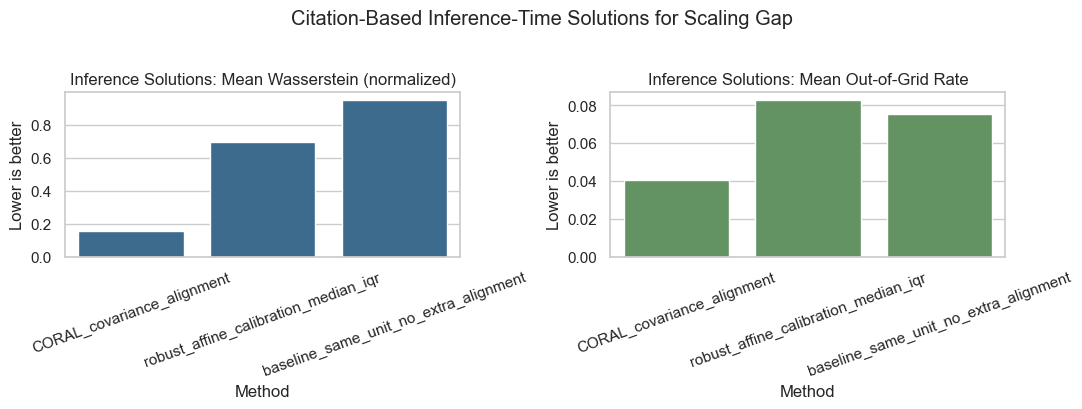

In [14]:
plot_df = citation_solution_table[citation_solution_table['scope'] == 'inference'].copy()

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))

sns.barplot(data=plot_df, x='method', y='mean_wasserstein_iqr_norm', ax=axes[0], color='#2f6d9a')
axes[0].set_title('Inference Solutions: Mean Wasserstein (normalized)')
axes[0].set_ylabel('Lower is better')
axes[0].set_xlabel('Method')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=plot_df, x='method', y='mean_out_of_grid_rate', ax=axes[1], color='#5b9a5b')
axes[1].set_title('Inference Solutions: Mean Out-of-Grid Rate')
axes[1].set_ylabel('Lower is better')
axes[1].set_xlabel('Method')
axes[1].tick_params(axis='x', rotation=20)

fig.suptitle('Citation-Based Inference-Time Solutions for Scaling Gap', y=1.02)
fig.tight_layout()
plt.show()

### Section Insight (Citation-Based Inference Solutions)

**Why**: We need a statistically grounded and deployable method to reduce scaling gap.

**How**: Compare baseline, robust affine, and CORAL with the same mismatch metrics.

**What**: Balance improvement against distortion and operational risk.

**When**: Final technical decision before production update.

**Where**: Inference preprocessing policy and model governance process.

**What we get**: A ranked, evidence-based choice with clear next steps.

Practical recommendation for your pipeline now:
1. Keep mandatory unit harmonization.
2. Add robust affine calibration parameters (from this notebook) to inference preprocessing.
3. Monitor Wasserstein and out-of-grid rates weekly; trigger recalibration/retraining only when thresholds are exceeded.

## Inside-Out Insights (What We Learn End-to-End)

### A. What is solved by this notebook
- Confirms where mismatch comes from (units, scaling, tails, and domain context).
- Shows which fixes are safe for real-time inference vs only good for research experiments.
- Produces reusable outputs for pipeline implementation, thesis chapters, and defense slides.

### B. Where this helps most
- **Pipeline reliability**: fewer confidence collapses due to distribution mismatch.
- **Model governance**: measurable drift indicators for recalibration/retraining triggers.
- **Thesis defensibility**: clear evidence chain from data diagnostics to engineering decisions.

### C. What to implement first in production
1. Mandatory unit harmonization gate.
2. Deploy low-distortion calibration (starting with robust affine).
3. Add weekly drift monitoring using Wasserstein + out-of-grid rates.
4. Escalate to stronger adaptation/retraining only when drift persists.

### D. What we gain
- Better alignment between production and training data.
- Better interpretability of confidence changes.
- Better auditability for mentor and thesis defense.

If you rerun this notebook on new production batches, you can track whether mismatch is getting better or worse over time.